# Comprehensive LSTM Study: Accuracy�Complexity Trade-offs

This notebook evaluates multiple Recurrent Neural Network (RNN) architectures for ambient temperature forecasting to analyze the trade-off between model complexity and predictive accuracy.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pandas import read_csv, DataFrame
import math, time
from keras.models import Sequential
from keras.layers import Dense, LSTM, GRU, SimpleRNN, Bidirectional
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

## Utility Functions & Configuration

In [3]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
    dataX, dataY = [], []
    for i in range(len(dataset)-look_back-1):
        a = dataset[i:(i+look_back), 0]
        dataX.append(a)
        dataY.append(dataset[i + look_back, 0])
    return np.array(dataX), np.array(dataY)

def mape(actual, predicted):
    """Mean Absolute Percentage Error"""
    mask = actual != 0
    return np.mean(np.abs((actual[mask] - predicted[mask]) / actual[mask])) * 100

def build_model(model_type, look_back, units=4):
    """Build different RNN architectures"""
    model = Sequential()
    if model_type == 'SimpleRNN':
        model.add(SimpleRNN(units, input_shape=(1, look_back)))
    elif model_type == 'GRU':
        model.add(GRU(units, input_shape=(1, look_back)))
    elif model_type == 'LSTM':
        model.add(LSTM(units, input_shape=(1, look_back)))
    elif model_type == 'BiLSTM':
        model.add(Bidirectional(LSTM(units), input_shape=(1, look_back)))
    elif model_type == 'StackedLSTM':
        model.add(LSTM(units, return_sequences=True, input_shape=(1, look_back)))
        model.add(LSTM(units))
    model.add(Dense(1))
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model

# Configuration
np.random.seed(7)
EPOCHS = 100
BATCH_SIZE = 32
UNITS = 4
MODEL_TYPES = ['SimpleRNN', 'GRU', 'LSTM', 'BiLSTM', 'StackedLSTM']
LOOK_BACKS = [1, 3, 5, 7, 14]

## Data Loading
Loading the large dataset (3,104 daily temperature readings from 2011-2019).

In [4]:
train_df = read_csv('training.csv', sep='\t', usecols=[1], engine='python').dropna()
test_df  = read_csv('testing.csv', usecols=[1], engine='python').dropna()

full_dataset = np.concatenate([train_df.values, test_df.values], axis=0).astype('float32')
scaler = MinMaxScaler(feature_range=(0, 1))
full_scaled = scaler.fit_transform(full_dataset)

train_size = len(train_df)
train_data = full_scaled[0:train_size, :]
test_data  = full_scaled[train_size:, :]

print(f"Dataset: {len(full_dataset)} samples (train={train_size}, test={len(test_df)})")

Dataset: 3103 samples (train=3071, test=32)


## Experiment 1: Multi-Model Comparison (fixed look_back=3)

In [5]:
look_back = 3
trainX, trainY = create_dataset(train_data, look_back)
testX, testY   = create_dataset(test_data, look_back)
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX  = np.reshape(testX,  (testX.shape[0],  1, testX.shape[1]))

exp1_results = []

for mtype in MODEL_TYPES:
    print(f"Training {mtype}...")
    np.random.seed(7)
    model = build_model(mtype, look_back, UNITS)
    n_params = model.count_params()

    t_start = time.time()
    history = model.fit(trainX, trainY, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    train_time = time.time() - t_start

    trainPred = scaler.inverse_transform(model.predict(trainX, verbose=0))
    testPred  = scaler.inverse_transform(model.predict(testX, verbose=0))
    trainY_inv = scaler.inverse_transform([trainY])[0]
    testY_inv  = scaler.inverse_transform([testY])[0]

    result = {
        'Model': mtype,
        'Params': n_params,
        'Train_Time_s': round(train_time, 2),
        'Train_RMSE': round(math.sqrt(mean_squared_error(trainY_inv, trainPred[:,0])), 2),
        'Test_RMSE':  round(math.sqrt(mean_squared_error(testY_inv, testPred[:,0])), 2),
        'Train_MAE':  round(mean_absolute_error(trainY_inv, trainPred[:,0]), 2),
        'Test_MAE':   round(mean_absolute_error(testY_inv, testPred[:,0]), 2),
        'Train_MAPE': round(mape(trainY_inv, trainPred[:,0]), 2),
        'Test_MAPE':  round(mape(testY_inv, testPred[:,0]), 2),
        'Train_R2':   round(r2_score(trainY_inv, trainPred[:,0]), 4),
        'Test_R2':    round(r2_score(testY_inv, testPred[:,0]), 4),
        'loss_history': history.history['loss'],
        'test_predictions': testPred[:,0],
        'test_actual': testY_inv
    }
    exp1_results.append(result)

df1 = DataFrame([{k: r[k] for k in result.keys() if k not in ['loss_history', 'test_predictions', 'test_actual']} for r in exp1_results])
display(df1)

Training SimpleRNN...
Training GRU...
Training LSTM...
Training BiLSTM...
Training StackedLSTM...


,Model,Params,Train_Time_s,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Train_MAPE,Test_MAPE,Train_R2,Test_R2
0,SimpleRNN,37,12.51,1.69,2.45,1.26,1.69,1.67,2.21,0.8543,0.2878
1,GRU,113,13.89,1.68,2.54,1.26,1.70,1.66,2.21,0.8546,0.2385
2,LSTM,133,12.82,1.70,2.52,1.27,1.69,1.67,2.21,0.8516,0.2488
3,BiLSTM,265,15.22,1.67,2.45,1.25,1.68,1.65,2.19,0.8563,0.2883
4,StackedLSTM,277,16.33,1.67,2.50,1.24,1.71,1.64,2.23,0.8578,0.2631


## Experiment 2: Look-back Window Sensitivity (LSTM only)

In [6]:
exp2_results = []

for lb in LOOK_BACKS:
    print(f"Training LSTM with look_back={lb}...")
    np.random.seed(7)
    trX, trY = create_dataset(train_data, lb)
    teX, teY = create_dataset(test_data, lb)
    trX = np.reshape(trX, (trX.shape[0], 1, trX.shape[1]))
    teX = np.reshape(teX, (teX.shape[0], 1, teX.shape[1]))

    model = build_model('LSTM', lb, UNITS)
    n_params = model.count_params()

    t_start = time.time()
    history = model.fit(trX, trY, epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    train_time = time.time() - t_start

    trPred = scaler.inverse_transform(model.predict(trX, verbose=0))
    tePred = scaler.inverse_transform(model.predict(teX, verbose=0))
    trY_inv = scaler.inverse_transform([trY])[0]
    teY_inv = scaler.inverse_transform([teY])[0]

    result = {
        'Look_Back': lb,
        'Params': n_params,
        'Train_Time_s': round(train_time, 2),
        'Train_RMSE': round(math.sqrt(mean_squared_error(trY_inv, trPred[:,0])), 2),
        'Test_RMSE':  round(math.sqrt(mean_squared_error(teY_inv, tePred[:,0])), 2),
        'Train_MAE':  round(mean_absolute_error(trY_inv, trPred[:,0]), 2),
        'Test_MAE':   round(mean_absolute_error(teY_inv, tePred[:,0]), 2),
        'Test_R2':    round(r2_score(teY_inv, tePred[:,0]), 4),
        'Final_Loss': round(history.history['loss'][-1], 6),
    }
    exp2_results.append(result)

df2 = DataFrame(exp2_results)
display(df2)

Training LSTM with look_back=1...
Training LSTM with look_back=3...
Training LSTM with look_back=5...
Training LSTM with look_back=7...
Training LSTM with look_back=14...


,Look_Back,Params,Train_Time_s,Train_RMSE,Test_RMSE,Train_MAE,Test_MAE,Test_R2,Final_Loss
0,1,101,12.79,1.69,2.50,1.26,1.75,0.2688,0.003769
1,3,133,12.82,1.67,2.47,1.24,1.68,0.2797,0.003672
2,5,165,13.63,1.65,2.59,1.23,1.79,0.1673,0.003592
3,7,197,13.62,1.64,2.72,1.22,1.87,0.1236,0.003547
4,14,309,13.45,1.64,3.12,1.22,2.17,0.0977,0.003623


## Visualizations

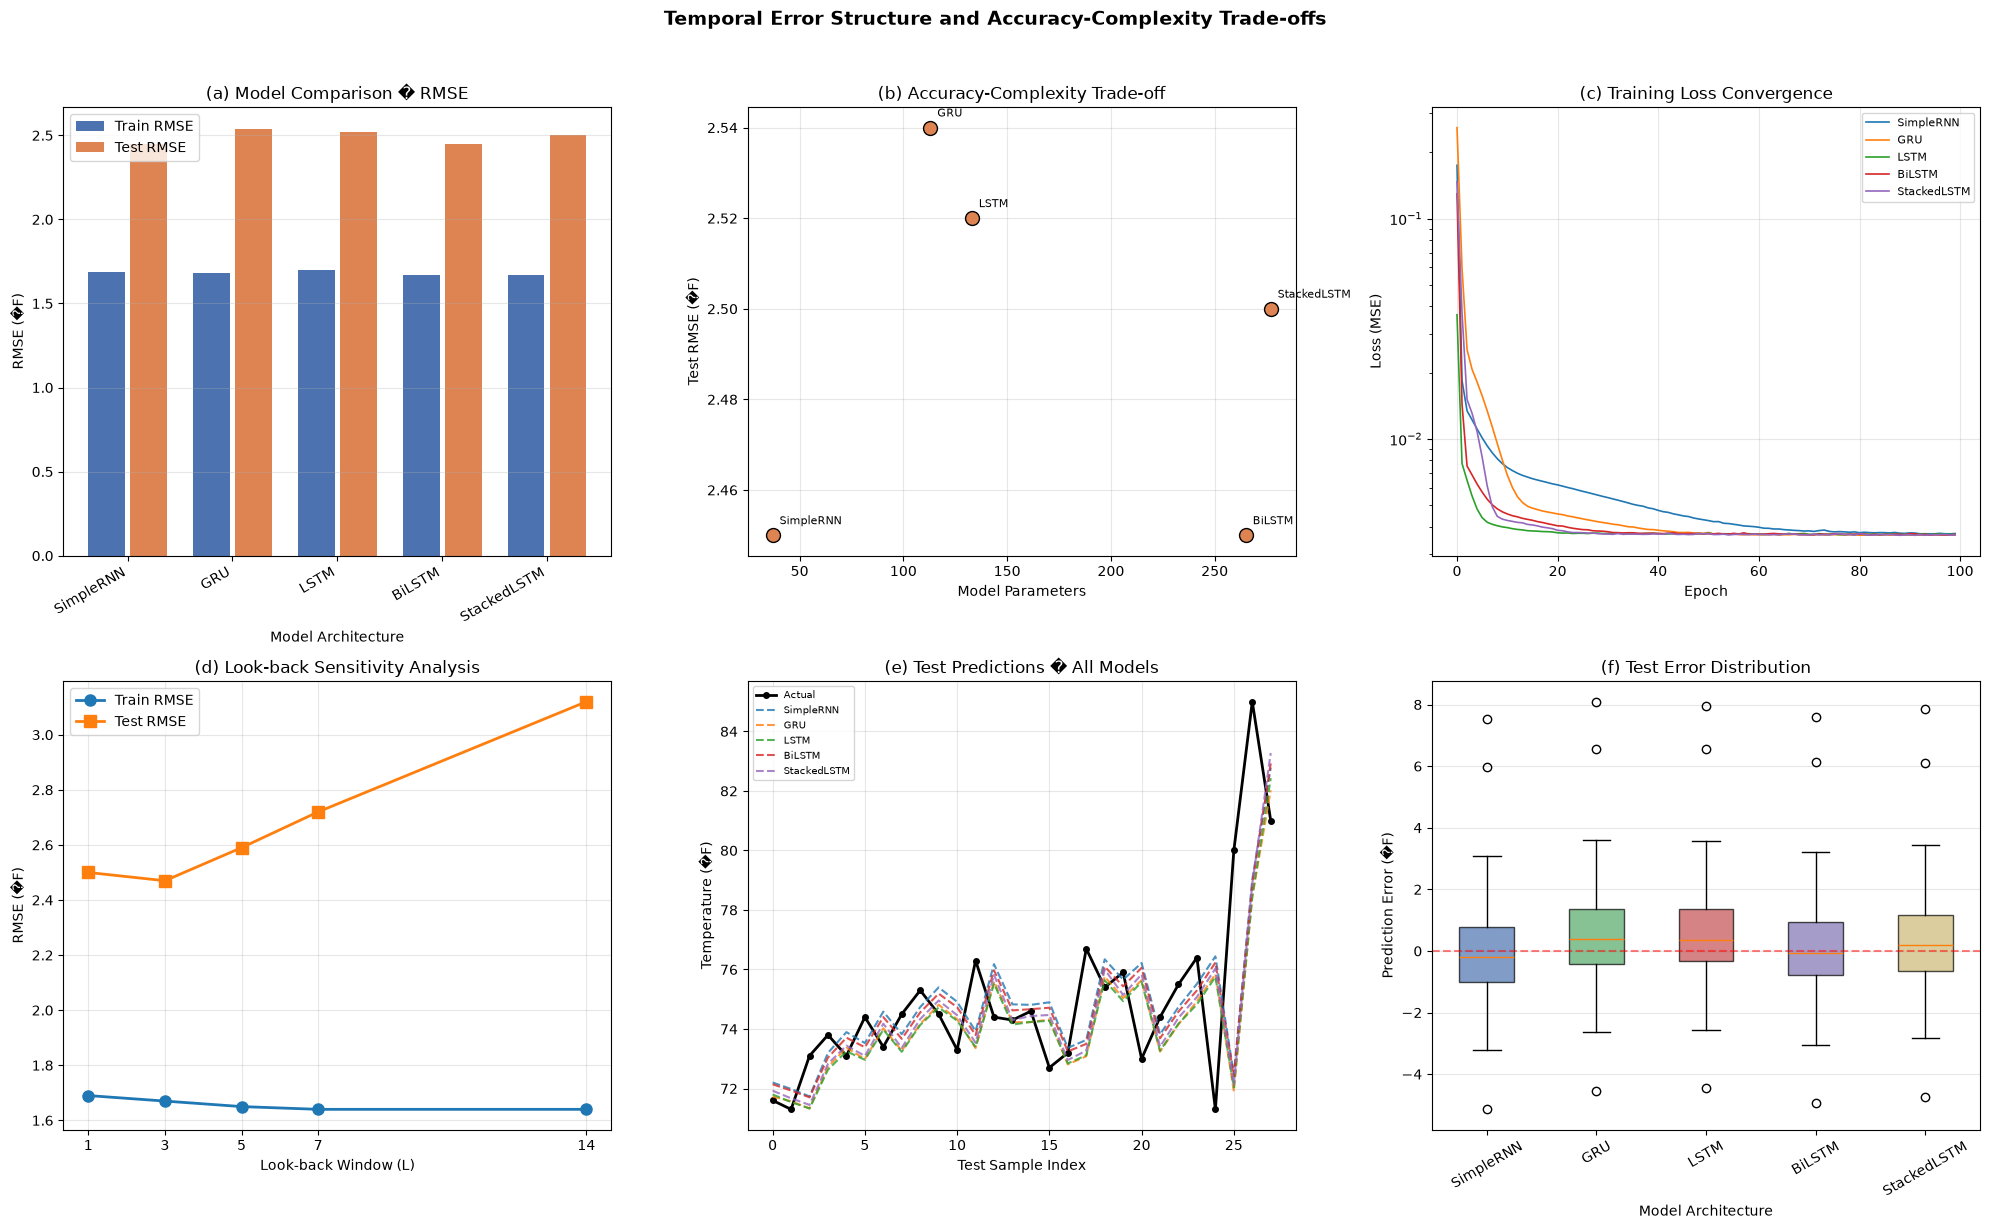

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# Fig 1: Model RMSE comparison (bar chart)
ax = axes[0, 0]
models = [r['Model'] for r in exp1_results]
train_rmse = [r['Train_RMSE'] for r in exp1_results]
test_rmse = [r['Test_RMSE'] for r in exp1_results]
x = np.arange(len(models))
ax.bar(x - 0.2, train_rmse, 0.35, label='Train RMSE', color='#4C72B0')
ax.bar(x + 0.2, test_rmse, 0.35, label='Test RMSE', color='#DD8452')
ax.set_xlabel('Model Architecture')
ax.set_ylabel('RMSE (�F)')
ax.set_title('(a) Model Comparison � RMSE')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=30, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

# Fig 2: Accuracy vs Complexity (params vs RMSE)
ax = axes[0, 1]
params = [r['Params'] for r in exp1_results]
ax.scatter(params, test_rmse, s=100, c='#DD8452', edgecolors='black', zorder=5)
for i, m in enumerate(models):
    ax.annotate(m, (params[i], test_rmse[i]), textcoords="offset points", xytext=(5, 8), fontsize=8)
ax.set_xlabel('Model Parameters')
ax.set_ylabel('Test RMSE (�F)')
ax.set_title('(b) Accuracy-Complexity Trade-off')
ax.grid(True, alpha=0.3)

# Fig 3: Training loss curves
ax = axes[0, 2]
for r in exp1_results:
    ax.plot(r['loss_history'], label=r['Model'], linewidth=1.2)
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (MSE)')
ax.set_title('(c) Training Loss Convergence')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
ax.set_yscale('log')

# Fig 4: Look-back sensitivity
ax = axes[1, 0]
lbs = [r['Look_Back'] for r in exp2_results]
lb_train = [r['Train_RMSE'] for r in exp2_results]
lb_test = [r['Test_RMSE'] for r in exp2_results]
ax.plot(lbs, lb_train, 'o-', label='Train RMSE', linewidth=2, markersize=8)
ax.plot(lbs, lb_test, 's-', label='Test RMSE', linewidth=2, markersize=8)
ax.set_xlabel('Look-back Window (L)')
ax.set_ylabel('RMSE (�F)')
ax.set_title('(d) Look-back Sensitivity Analysis')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xticks(lbs)

# Fig 5: Test predictions overlay
ax = axes[1, 1]
test_actual_plotted = False
for r in exp1_results:
    if not test_actual_plotted:
        ax.plot(r['test_actual'], 'k-o', label='Actual', linewidth=2, markersize=4)
        test_actual_plotted = True
    ax.plot(r['test_predictions'], '--', label=r['Model'], linewidth=1.5, alpha=0.8)
ax.set_xlabel('Test Sample Index')
ax.set_ylabel('Temperature (�F)')
ax.set_title('(e) Test Predictions � All Models')
ax.legend(fontsize=7)
ax.grid(True, alpha=0.3)

# Fig 6: Error distribution (box plot)
ax = axes[1, 2]
errors = []
labels = []
for r in exp1_results:
    err = r['test_actual'] - r['test_predictions']
    errors.append(err)
    labels.append(r['Model'])
bp = ax.boxplot(errors, tick_labels=labels, patch_artist=True)
colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_xlabel('Model Architecture')
ax.set_ylabel('Prediction Error (�F)')
ax.set_title('(f) Test Error Distribution')
ax.axhline(y=0, color='r', linestyle='--', alpha=0.5)
ax.tick_params(axis='x', rotation=30)
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('Temporal Error Structure and Accuracy-Complexity Trade-offs', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()